# Experiment 4 — Data Exploration (EDA)

**CSE4007L — Applications of Machine Learning in Industry**  
Com-Project 2: Fake News Detection

Krishna Kaushik · 230160223030 · Section-A Group 2

**Before running:** run `experiment3.ipynb` first — this notebook reads the `train.csv` it creates.

    pip3 install pandas scikit-learn matplotlib


In [2]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

REAL_C, FAKE_C = "#2A6FB5", "#D97706"        # colour-blind-safe pair

def style(ax, title, xlabel):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E6E6E6", lw=0.8); ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel(xlabel, fontsize=9)

## 1. Load the cleaned dataset

In [3]:
df = pd.read_csv("train.csv").dropna()   # training split from Experiment 3
real = df[df.label == 0]["text"]
fake = df[df.label == 1]["text"]
print("Records:", len(df), " Real:", len(real), " Fake:", len(fake))

Records: 27056  Real: 14837  Fake: 12219


## 2. Article length by class

         count   mean    std   min    25%    50%    75%     max
label                                                          
0      14837.0  397.2  280.7  28.0  153.0  368.0  536.0  5227.0
1      12219.0  449.0  366.0   9.0  301.0  397.0  526.0  8294.0

Length distribution (% of each class):
label             0     1
words                    
(0, 100]       13.9   6.8
(100, 200]     15.4   6.7
(200, 300]     11.2  11.5
(300, 400]     15.5  25.9
(400, 600]     23.4  32.7
(600, 1000]    17.6  12.8
(1000, 99999]   3.0   3.6


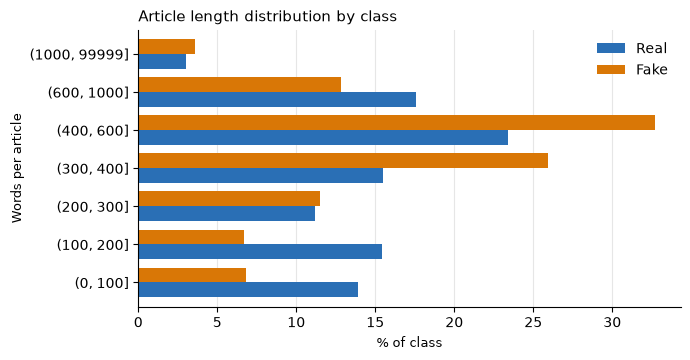

In [4]:
df["words"] = df["text"].str.split().str.len()
print(df.groupby("label")["words"].describe().round(1))

bins = [0, 100, 200, 300, 400, 600, 1000, 99999]
pct = pd.crosstab(pd.cut(df.words, bins), df.label, normalize="columns").mul(100).round(1)
print("\nLength distribution (% of each class):")
print(pct)

ax = pct.plot.barh(color=[REAL_C, FAKE_C], figsize=(7, 3.6), width=0.78)
ax.legend(["Real", "Fake"], frameon=False); ax.set_ylabel("Words per article", fontsize=9)
style(ax, "Article length distribution by class", "% of class")
plt.savefig("fig1_length.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Most frequent words per class

In [5]:
def top_terms(texts, ngram=1, n=10):
    cv = CountVectorizer(ngram_range=(ngram, ngram), stop_words="english", max_features=2000)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=cv.get_feature_names_out()).nlargest(n)

print("REAL - top words:\n", top_terms(real).to_string())
print("\nFAKE - top words:\n", top_terms(fake).to_string())

REAL - top words:
 said          68753
trump         42371
president     19723
state         15002
government    13214
house         12543
new           12317
republican    11733
states        11534
united        10728

FAKE - top words:
 trump        54019
said         17535
president    15213
people       15042
just         12735
donald       11335
obama        10553
clinton      10331
like         10327
video         8794


## 4. Most frequent bigrams per class

In [6]:
print("REAL - top bigrams:\n", top_terms(real, 2).to_string())
print("\nFAKE - top bigrams:\n", top_terms(fake, 2).to_string())

REAL - top bigrams:
 united states       8371
donald trump        7157
white house         6345
north korea         4348
president donald    4109
new york            3423
prime minister      2932
said statement      2739
islamic state       2615
trump said          2502

FAKE - top bigrams:
 donald trump       10410
featured image      5605
hillary clinton     4125
white house         3898
united states       3517
pic twitter         3425
twitter com         3411
getty images        2853
president obama     2545
new york            2338


## 5. Most distinctive words per class

Most FAKE-leaning words:
                  real   fake  ratio
featured          0.0  28.66  29.66
com               0.0  19.16  20.16
pic               0.0  16.79  17.79
gop               0.0  15.21  16.21
images            0.0  15.20  16.20
image             1.1  32.94  16.15
realdonaldtrump   0.0  14.32  15.32
getty             0.0  14.16  15.16

Most REAL-leaning words:
                real  fake  ratio
eu            16.13  0.00   0.06
parliament     8.86  0.00   0.10
ministry       8.81  0.00   0.10
myanmar        8.36  0.00   0.11
brexit         7.10  0.00   0.12
nov            6.97  0.00   0.13
minister      25.12  2.33   0.13
independence   6.82  0.00   0.13


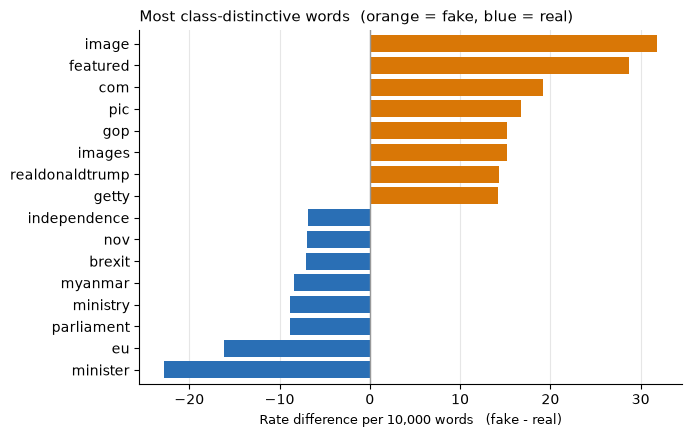

Saved: fig1_length.png, fig2_distinctive.png


In [7]:
def rate(texts):                      # occurrences per 10,000 words
    cv = CountVectorizer(stop_words="english", max_features=3000)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    s = pd.Series(counts, index=cv.get_feature_names_out())
    return s / s.sum() * 10000

tab = pd.DataFrame({"real": rate(real), "fake": rate(fake)}).fillna(0)
tab["ratio"] = (tab.fake + 1) / (tab.real + 1)
print("Most FAKE-leaning words:\n", tab.nlargest(8, "ratio").round(2).to_string())
print("\nMost REAL-leaning words:\n", tab.nsmallest(8, "ratio").round(2).to_string())

top = pd.concat([tab.nlargest(8, "ratio"), tab.nsmallest(8, "ratio")])
diff = (top.fake - top.real).sort_values()
ax = diff.plot.barh(figsize=(7, 4.6), width=0.78,
                    color=[FAKE_C if v > 0 else REAL_C for v in diff])
ax.axvline(0, color="#999999", lw=1)
style(ax, "Most class-distinctive words  (orange = fake, blue = real)",
      "Rate difference per 10,000 words   (fake - real)")
plt.savefig("fig2_distinctive.png", dpi=150, bbox_inches="tight"); plt.show()
print("Saved: fig1_length.png, fig2_distinctive.png")

## 6. Key insights

In [8]:
print("Mean words  - real:", round(real.str.split().str.len().mean(), 1),
      "| fake:", round(fake.str.split().str.len().mean(), 1))
print("Vocabulary  - real:", len(set(" ".join(real.head(5000)).split())),
      "| fake:", len(set(" ".join(fake.head(5000)).split())))
print("Overlap of top-20 words between classes:",
      len(set(top_terms(real, 1, 20).index) & set(top_terms(fake, 1, 20).index)), "/ 20")

Mean words  - real: 397.2 | fake: 449.0
Vocabulary  - real: 36574 | fake: 47210
Overlap of top-20 words between classes: 9 / 20
